In [1]:
# ==========================================================
# Stage 5 – Step 1.1 : Imports
# ==========================================================

from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

import torchvision.models as models
import timm

print("=" * 70)
print("Stage 5 - Explainable AI Analysis")
print("=" * 70)

print("PyTorch :", torch.__version__)
print("OpenCV  :", cv2.__version__)
print("timm    :", timm.__version__)

Stage 5 - Explainable AI Analysis
PyTorch : 2.10.0
OpenCV  : 4.13.0
timm    : 1.0.25


In [2]:
# ==========================================================
# Stage 5 – Step 1.2 : Device Configuration
# ==========================================================

if torch.backends.mps.is_available():
    device = torch.device("mps")
    device_name = "Apple Silicon GPU (MPS)"

elif torch.cuda.is_available():
    device = torch.device("cuda")
    device_name = torch.cuda.get_device_name(0)

else:
    device = torch.device("cpu")
    device_name = "CPU"

print("=" * 70)
print("Device Configuration")
print("=" * 70)

print("Device      :", device)
print("Description :", device_name)

Device Configuration
Device      : mps
Description : Apple Silicon GPU (MPS)


In [3]:
# ==========================================================
# Stage 5 – Step 1.3 : Project Paths
# ==========================================================

project_root = (
    Path.home()
    / "Desktop"
    / "Mtech_final_project"
    / "SegFusionFormer"
)

dataset_dir = project_root / "dataset"

images_dir = dataset_dir / "images"
lung_masks_dir = dataset_dir / "lung_masks"

models_dir = project_root / "models"
outputs_dir = project_root / "outputs"

results_dir = project_root / "results"

xai_dir = results_dir / "figures" / "xai"
xai_dir.mkdir(
    parents=True,
    exist_ok=True
)

unet_path = (
    models_dir /
    "best_unet.pth"
)

classifier_path = (
    models_dir /
    "best_segfusionformer.pth"
)

csv_path = (
    dataset_dir /
    "Data_Entry_2017.csv"
)

print("=" * 70)
print("Stage 5 Paths")
print("=" * 70)

print("Project Root :", project_root)
print("Images       :", images_dir)
print("Lung Masks   :", lung_masks_dir)
print("U-Net        :", unet_path)
print("Classifier   :", classifier_path)
print("CSV          :", csv_path)
print("XAI Outputs  :", xai_dir)

print("\nExistence Check")
print("-" * 70)

print("Images      :", images_dir.exists())
print("Masks       :", lung_masks_dir.exists())
print("U-Net       :", unet_path.exists())
print("Classifier  :", classifier_path.exists())
print("CSV         :", csv_path.exists())

Stage 5 Paths
Project Root : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer
Images       : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/dataset/images
Lung Masks   : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/dataset/lung_masks
U-Net        : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/models/best_unet.pth
Classifier   : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/models/best_segfusionformer.pth
CSV          : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/dataset/Data_Entry_2017.csv
XAI Outputs  : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/figures/xai

Existence Check
----------------------------------------------------------------------
Images      : True
Masks       : True
U-Net       : True
Classifier  : True
CSV         : True


In [4]:
# ==========================================================
# Stage 5 – Step 1.4 : Disease Classes
# ==========================================================

DISEASES = [
    "Atelectasis",
    "Cardiomegaly",
    "Effusion",
    "Infiltration",
    "Mass",
    "Nodule",
    "Pneumonia",
    "Pneumothorax",
    "Consolidation",
    "Edema",
    "Emphysema",
    "Fibrosis",
    "Pleural_Thickening",
    "Hernia"
]

print("=" * 70)
print("Disease Classes")
print("=" * 70)

for i, disease in enumerate(DISEASES):
    print(f"{i+1:2d}. {disease}")

print("\nNumber of Classes :", len(DISEASES))

Disease Classes
 1. Atelectasis
 2. Cardiomegaly
 3. Effusion
 4. Infiltration
 5. Mass
 6. Nodule
 7. Pneumonia
 8. Pneumothorax
 9. Consolidation
10. Edema
11. Emphysema
12. Fibrosis
13. Pleural_Thickening
14. Hernia

Number of Classes : 14


In [5]:
# ==========================================================
# Stage 5 – Step 2.1 : Rebuild U-Net Architecture
# ==========================================================

class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class Down(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.MaxPool2d(2),
            DoubleConv(in_channels, out_channels)
        )

    def forward(self, x):
        return self.block(x)


class Up(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.up = nn.ConvTranspose2d(
            in_channels,
            in_channels // 2,
            kernel_size=2,
            stride=2
        )

        self.conv = DoubleConv(
            in_channels,
            out_channels
        )

    def forward(self, x1, x2):

        x1 = self.up(x1)

        if x1.shape[2:] != x2.shape[2:]:
            x1 = F.interpolate(
                x1,
                size=x2.shape[2:],
                mode="bilinear",
                align_corners=False
            )

        x = torch.cat([x2, x1], dim=1)

        return self.conv(x)


class UNet(nn.Module):

    def __init__(self, in_channels=1, out_channels=1):
        super().__init__()

        self.inc = DoubleConv(in_channels, 32)

        self.down1 = Down(32, 64)
        self.down2 = Down(64, 128)
        self.down3 = Down(128, 256)
        self.down4 = Down(256, 512)

        self.up1 = Up(512, 256)
        self.up2 = Up(256, 128)
        self.up3 = Up(128, 64)
        self.up4 = Up(64, 32)

        self.outc = nn.Conv2d(
            32,
            out_channels,
            kernel_size=1
        )

    def forward(self, x):

        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)

        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)

        return self.outc(x)


print("✅ U-Net architecture created.")

✅ U-Net architecture created.


In [6]:
# ==========================================================
# Stage 5 – Step 2.2 : Load Best U-Net
# ==========================================================

unet_model = UNet(
    in_channels=1,
    out_channels=1
).to(device)

unet_checkpoint = torch.load(
    unet_path,
    map_location=device
)

# Your Stage 3 checkpoint stores model_state_dict
if isinstance(unet_checkpoint, dict) and "model_state_dict" in unet_checkpoint:
    unet_model.load_state_dict(
        unet_checkpoint["model_state_dict"]
    )
else:
    unet_model.load_state_dict(
        unet_checkpoint
    )

unet_model.eval()

print("=" * 70)
print("U-Net Loaded")
print("=" * 70)

print("Device :", next(unet_model.parameters()).device)

if isinstance(unet_checkpoint, dict):
    print(
        "Validation Dice :",
        unet_checkpoint.get("val_dice", "Not stored")
    )

U-Net Loaded
Device : mps:0
Validation Dice : 0.9600503588544911


In [7]:
# ==========================================================
# Stage 5 – Step 2.3 : Mask-Guided Attention
# ==========================================================

class MaskGuidedAttention(nn.Module):

    def __init__(self):
        super().__init__()

        self.attention_generator = nn.Sequential(

            nn.Conv2d(2, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),

            nn.Conv2d(16, 8, 3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(8, 1, 1),

            nn.Sigmoid()
        )

        self.alpha = nn.Parameter(
            torch.tensor(1.0)
        )

    def forward(self, x):

        image = x[:, 0:1]
        mask = x[:, 1:2]

        learned_attention = self.attention_generator(x)

        guided_attention = (
            learned_attention * mask
        )

        enhanced_image = image * (
            1.0 + self.alpha * guided_attention
        )

        enhanced_image = torch.clamp(
            enhanced_image,
            0.0,
            1.0
        )

        enhanced_rgb = enhanced_image.repeat(
            1,
            3,
            1,
            1
        )

        return enhanced_rgb, guided_attention

In [8]:
# ==========================================================
# Stage 5 – Step 2.4 : Feature Extraction Branches
# ==========================================================

class EfficientNetBranch(nn.Module):

    def __init__(self):
        super().__init__()

        backbone = models.efficientnet_b0(
            weights=None
        )

        self.features = backbone.features
        self.pool = nn.AdaptiveAvgPool2d(1)

        self.feature_dim = 1280

    def forward(self, x):

        x = self.features(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)

        return x


class MaxViTBranch(nn.Module):

    def __init__(self):
        super().__init__()

        self.backbone = timm.create_model(
            "maxvit_tiny_tf_224.in1k",
            pretrained=False,
            num_classes=0,
            global_pool="avg"
        )

        self.feature_dim = self.backbone.num_features

    def forward(self, x):
        return self.backbone(x)

In [9]:
# ==========================================================
# Stage 5 – Step 2.5 : Adaptive Feature Fusion
# ==========================================================

class AdaptiveFeatureFusion(nn.Module):

    def __init__(
        self,
        cnn_dim,
        maxvit_dim,
        fusion_dim=512,
        dropout=0.3
    ):
        super().__init__()

        self.cnn_projection = nn.Sequential(
            nn.Linear(cnn_dim, fusion_dim),
            nn.ReLU(inplace=True)
        )

        self.maxvit_projection = nn.Sequential(
            nn.Linear(maxvit_dim, fusion_dim),
            nn.ReLU(inplace=True)
        )

        self.gate = nn.Sequential(
            nn.Linear(fusion_dim * 2, fusion_dim),
            nn.ReLU(inplace=True),

            nn.Linear(fusion_dim, 2),
            nn.Softmax(dim=1)
        )

        self.refine = nn.Sequential(
            nn.LayerNorm(fusion_dim),
            nn.Dropout(dropout)
        )

    def forward(self, cnn_features, maxvit_features):

        cnn_proj = self.cnn_projection(
            cnn_features
        )

        maxvit_proj = self.maxvit_projection(
            maxvit_features
        )

        combined = torch.cat(
            [cnn_proj, maxvit_proj],
            dim=1
        )

        weights = self.gate(combined)

        cnn_weight = weights[:, 0:1]
        maxvit_weight = weights[:, 1:2]

        fused = (
            cnn_weight * cnn_proj +
            maxvit_weight * maxvit_proj
        )

        fused = self.refine(fused)

        return fused, weights

In [10]:
# ==========================================================
# Stage 5 – Step 2.6 : Complete SegFusionFormer
# ==========================================================

class SegFusionFormer(nn.Module):

    def __init__(self, num_classes=14):
        super().__init__()

        self.mask_attention = MaskGuidedAttention()

        self.cnn_branch = EfficientNetBranch()

        self.maxvit_branch = MaxViTBranch()

        self.fusion = AdaptiveFeatureFusion(
            cnn_dim=self.cnn_branch.feature_dim,
            maxvit_dim=self.maxvit_branch.feature_dim,
            fusion_dim=512,
            dropout=0.3
        )

        self.classifier = nn.Sequential(

            nn.LayerNorm(512),

            nn.Linear(512, 256),
            nn.GELU(),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.GELU(),
            nn.Dropout(0.2),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        enhanced_image, attention_map = self.mask_attention(x)

        cnn_features = self.cnn_branch(
            enhanced_image
        )

        maxvit_features = self.maxvit_branch(
            enhanced_image
        )

        fused_features, fusion_weights = self.fusion(
            cnn_features,
            maxvit_features
        )

        logits = self.classifier(
            fused_features
        )

        return (
            logits,
            fusion_weights,
            attention_map
        )


print("✅ SegFusionFormer architecture created.")

✅ SegFusionFormer architecture created.


In [11]:
# ==========================================================
# Stage 5 – Step 2.7 : Load Best SegFusionFormer
# ==========================================================

best_model = SegFusionFormer(
    num_classes=len(DISEASES)
).to(device)

classifier_checkpoint = torch.load(
    classifier_path,
    map_location=device
)

if (
    isinstance(classifier_checkpoint, dict)
    and "model_state_dict" in classifier_checkpoint
):
    best_model.load_state_dict(
        classifier_checkpoint["model_state_dict"]
    )
else:
    best_model.load_state_dict(
        classifier_checkpoint
    )

best_model.eval()

print("=" * 70)
print("SegFusionFormer Loaded Successfully")
print("=" * 70)

print(
    "Device :",
    next(best_model.parameters()).device
)

print(
    "Classes:",
    len(DISEASES)
)

SegFusionFormer Loaded Successfully
Device : mps:0
Classes: 14


In [12]:
# ==========================================================
# Stage 5 – Step 2.8 : Model Verification
# ==========================================================

dummy_input = torch.randn(
    1,
    2,
    224,
    224
).to(device)

with torch.no_grad():

    logits, fusion_weights, attention_map = best_model(
        dummy_input
    )

print("=" * 70)
print("Stage 5 Model Verification")
print("=" * 70)

print("Input           :", dummy_input.shape)
print("Logits          :", logits.shape)
print("Fusion Weights  :", fusion_weights.shape)
print("Attention Map   :", attention_map.shape)

print("\n✅ Both trained models are ready for XAI analysis.")

Stage 5 Model Verification
Input           : torch.Size([1, 2, 224, 224])
Logits          : torch.Size([1, 14])
Fusion Weights  : torch.Size([1, 2])
Attention Map   : torch.Size([1, 1, 224, 224])

✅ Both trained models are ready for XAI analysis.


In [13]:
# ==========================================================
# Stage 5 – Step 3.1 : Load NIH Metadata
# ==========================================================

df = pd.read_csv(csv_path)

# Remove unwanted unnamed columns
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

print("=" * 70)
print("NIH Metadata Loaded")
print("=" * 70)

print("Rows    :", len(df))
print("Columns :", len(df.columns))

display(
    df[
        [
            "Image Index",
            "Finding Labels",
            "Patient ID"
        ]
    ].head()
)

NIH Metadata Loaded
Rows    : 112120
Columns : 11


,Image Index,Finding Labels,Patient ID
0,00000001_000.png,Cardiomegaly,1
1,00000001_001.png,Cardiomegaly|Emphysema,1
2,00000001_002.png,Cardiomegaly|Effusion,1
3,00000002_000.png,No Finding,2
4,00000003_000.png,Hernia,3


In [14]:
# ==========================================================
# Stage 5 – Step 3.2 : Multi-Label Encoding
# ==========================================================

label_sets = df["Finding Labels"].fillna("").apply(
    lambda x: set(x.split("|"))
)

for disease in DISEASES:

    df[disease] = label_sets.apply(
        lambda labels: 1.0 if disease in labels else 0.0
    ).astype(np.float32)

print("=" * 70)
print("Disease Labels Encoded")
print("=" * 70)

print("Number of Diseases :", len(DISEASES))

display(
    df[
        ["Image Index", "Finding Labels"] + DISEASES
    ].head()
)

Disease Labels Encoded
Number of Diseases : 14


,Image Index,Finding Labels,Atelectasis,Cardiomegaly,Effusion,Infiltration,Mass,Nodule,Pneumonia,Pneumothorax,Consolidation,Edema,Emphysema,Fibrosis,Pleural_Thickening,Hernia
0,00000001_000.png,Cardiomegaly,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,00000001_001.png,Cardiomegaly|Emphysema,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,00000001_002.png,Cardiomegaly|Effusion,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,00000002_000.png,No Finding,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,00000003_000.png,Hernia,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [15]:
# ==========================================================
# Stage 5 – Step 3.3 : Create Image and Mask Paths
# ==========================================================

df["image_path"] = df["Image Index"].apply(
    lambda x: images_dir / x
)

df["mask_path"] = df["Image Index"].apply(
    lambda x: lung_masks_dir / f"{Path(x).stem}_mask.png"
)

df["image_exists"] = df["image_path"].apply(
    lambda x: x.exists()
)

df["mask_exists"] = df["mask_path"].apply(
    lambda x: x.exists()
)

print("=" * 70)
print("File Verification")
print("=" * 70)

print("Images Found :", df["image_exists"].sum())
print("Masks Found  :", df["mask_exists"].sum())

print("Missing Images :", (~df["image_exists"]).sum())
print("Missing Masks  :", (~df["mask_exists"]).sum())

File Verification
Images Found : 112120
Masks Found  : 112120
Missing Images : 0
Missing Masks  : 0


In [16]:
# ==========================================================
# Stage 5 – Step 3.4 : Load Optimized Disease Thresholds
# ==========================================================

threshold_path = (
    project_root
    / "results"
    / "tables"
    / "optimal_thresholds.csv"
)

threshold_df = pd.read_csv(
    threshold_path
)

print("=" * 70)
print("Optimized Thresholds Loaded")
print("=" * 70)

display(threshold_df)

optimal_thresholds = threshold_df["Threshold"].values.astype(
    np.float32
)

print("\nThreshold Shape :", optimal_thresholds.shape)

Optimized Thresholds Loaded


,Disease,Threshold
0,Atelectasis,0.650527
1,Cardiomegaly,0.971943
2,Effusion,0.734151
3,Infiltration,0.516267
4,Mass,0.848788
5,Nodule,0.746247
6,Pneumonia,0.815586
7,Pneumothorax,0.874804
8,Consolidation,0.730184
9,Edema,0.948308



Threshold Shape : (14,)


In [17]:
# ==========================================================
# Stage 5 – Step 3.5 : Select Representative Disease Cases
# ==========================================================

representative_cases = {}

for disease in DISEASES:

    disease_rows = df[
        df[disease] == 1.0
    ]

    # Keep only samples with valid image and mask
    disease_rows = disease_rows[
        disease_rows["image_exists"]
        &
        disease_rows["mask_exists"]
    ]

    if len(disease_rows) > 0:

        representative_cases[disease] = disease_rows.iloc[0]


print("=" * 70)
print("Representative XAI Cases")
print("=" * 70)

for disease, row in representative_cases.items():

    print(
        f"{disease:20s} -> "
        f"{row['Image Index']}"
    )

print(
    "\nNumber of diseases with representative cases:",
    len(representative_cases)
)

Representative XAI Cases
Atelectasis          -> 00000011_006.png
Cardiomegaly         -> 00000001_000.png
Effusion             -> 00000001_002.png
Infiltration         -> 00000003_003.png
Mass                 -> 00000004_000.png
Nodule               -> 00000004_000.png
Pneumonia            -> 00000013_010.png
Pneumothorax         -> 00000013_001.png
Consolidation        -> 00000032_012.png
Edema                -> 00000032_001.png
Emphysema            -> 00000001_001.png
Fibrosis             -> 00000020_001.png
Pleural_Thickening   -> 00000013_003.png
Hernia               -> 00000003_000.png

Number of diseases with representative cases: 14


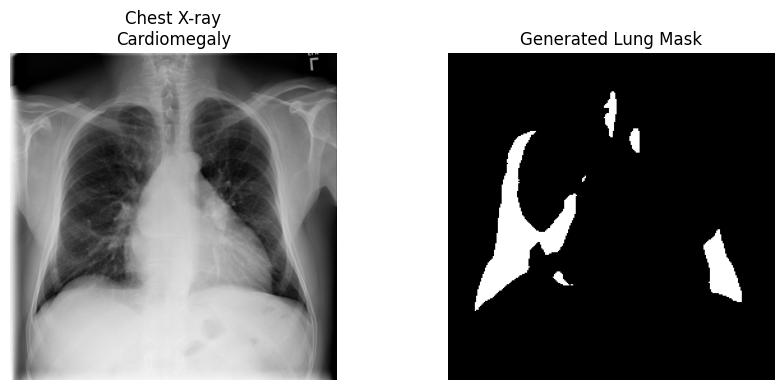

In [18]:
# ==========================================================
# Stage 5 – Step 3.6 : Visualize One Representative Case
# ==========================================================

example_disease = "Cardiomegaly"

sample_row = representative_cases[
    example_disease
]

image = cv2.imread(
    str(sample_row["image_path"]),
    cv2.IMREAD_GRAYSCALE
)

mask = cv2.imread(
    str(sample_row["mask_path"]),
    cv2.IMREAD_GRAYSCALE
)

plt.figure(figsize=(9, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title(
    f"Chest X-ray\n{sample_row['Finding Labels']}"
)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("Generated Lung Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

In [19]:
# ==========================================================
# Stage 5 – Step 4.1 : Prepare XAI Input
# ==========================================================

def prepare_xai_input(image_path, mask_path, image_size=224):

    # Read image
    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        raise RuntimeError(
            f"Unable to read image: {image_path}"
        )

    # Read lung mask
    mask = cv2.imread(
        str(mask_path),
        cv2.IMREAD_GRAYSCALE
    )

    if mask is None:
        raise RuntimeError(
            f"Unable to read mask: {mask_path}"
        )

    # Resize
    image = cv2.resize(
        image,
        (image_size, image_size)
    )

    mask = cv2.resize(
        mask,
        (image_size, image_size),
        interpolation=cv2.INTER_NEAREST
    )

    # Normalize
    image = image.astype(np.float32) / 255.0
    mask = mask.astype(np.float32) / 255.0

    # Binary mask
    mask = (mask > 0.5).astype(np.float32)

    # Tensor conversion
    image_tensor = torch.from_numpy(
        image
    ).unsqueeze(0)

    mask_tensor = torch.from_numpy(
        mask
    ).unsqueeze(0)

    # Combine:
    # Channel 0 = X-ray
    # Channel 1 = Lung mask
    input_tensor = torch.cat(
        [image_tensor, mask_tensor],
        dim=0
    )

    # Add batch dimension
    input_tensor = input_tensor.unsqueeze(0)

    return input_tensor, image, mask


print("✅ XAI input preparation function created.")

✅ XAI input preparation function created.


In [20]:
# ==========================================================
# Stage 5 – Step 4.2 : XAI Prediction Helper
# ==========================================================

def analyze_xai_case(
    model,
    image_path,
    mask_path,
    thresholds,
    device
):

    # Prepare input
    input_tensor, image_np, mask_np = prepare_xai_input(
        image_path=image_path,
        mask_path=mask_path
    )

    input_tensor = input_tensor.to(device)

    model.eval()

    with torch.no_grad():

        logits, fusion_weights, attention_map = model(
            input_tensor
        )

        probabilities = torch.sigmoid(
            logits
        )[0].cpu().numpy()

    # Apply disease-specific thresholds
    predictions = (
        probabilities >= thresholds
    ).astype(int)

    # Build result table
    rows = []

    for disease, prob, threshold, pred in zip(
        DISEASES,
        probabilities,
        thresholds,
        predictions
    ):

        rows.append({
            "Disease": disease,
            "Probability": float(prob),
            "Threshold": float(threshold),
            "Predicted": int(pred)
        })

    prediction_df = pd.DataFrame(rows)

    return {
        "input_tensor": input_tensor,
        "image": image_np,
        "mask": mask_np,
        "probabilities": probabilities,
        "predictions": predictions,
        "prediction_df": prediction_df,
        "attention_map": (
            attention_map[0, 0]
            .detach()
            .cpu()
            .numpy()
        ),
        "fusion_weights": (
            fusion_weights[0]
            .detach()
            .cpu()
            .numpy()
        )
    }


print("✅ XAI analysis helper created.")

✅ XAI analysis helper created.


In [21]:
# ==========================================================
# Stage 5 – Step 4.3 : Test XAI Helper
# ==========================================================

example_disease = "Cardiomegaly"

sample_row = representative_cases[
    example_disease
]

xai_result = analyze_xai_case(
    model=best_model,
    image_path=sample_row["image_path"],
    mask_path=sample_row["mask_path"],
    thresholds=optimal_thresholds,
    device=device
)

print("=" * 70)
print("XAI CASE ANALYSIS")
print("=" * 70)

print("Image        :", sample_row["Image Index"])
print("Ground Truth :", sample_row["Finding Labels"])

print("\nFusion Weights")
print(
    "CNN    :",
    f"{xai_result['fusion_weights'][0]:.4f}"
)

print(
    "MaxViT :",
    f"{xai_result['fusion_weights'][1]:.4f}"
)

print(
    "Sum    :",
    f"{xai_result['fusion_weights'].sum():.4f}"
)

print("\nPredicted Diseases")
print("-" * 70)

positive_predictions = (
    xai_result["prediction_df"]
    [xai_result["prediction_df"]["Predicted"] == 1]
    .sort_values(
        "Probability",
        ascending=False
    )
)

if len(positive_predictions) == 0:

    print("No disease predicted above optimized thresholds.")

else:

    display(
        positive_predictions[
            [
                "Disease",
                "Probability",
                "Threshold"
            ]
        ].round(4)
    )

XAI CASE ANALYSIS
Image        : 00000001_000.png
Ground Truth : Cardiomegaly

Fusion Weights
CNN    : 1.0000
MaxViT : 0.0000
Sum    : 1.0000

Predicted Diseases
----------------------------------------------------------------------


,Disease,Probability,Threshold
1,Cardiomegaly,0.9961,0.9719


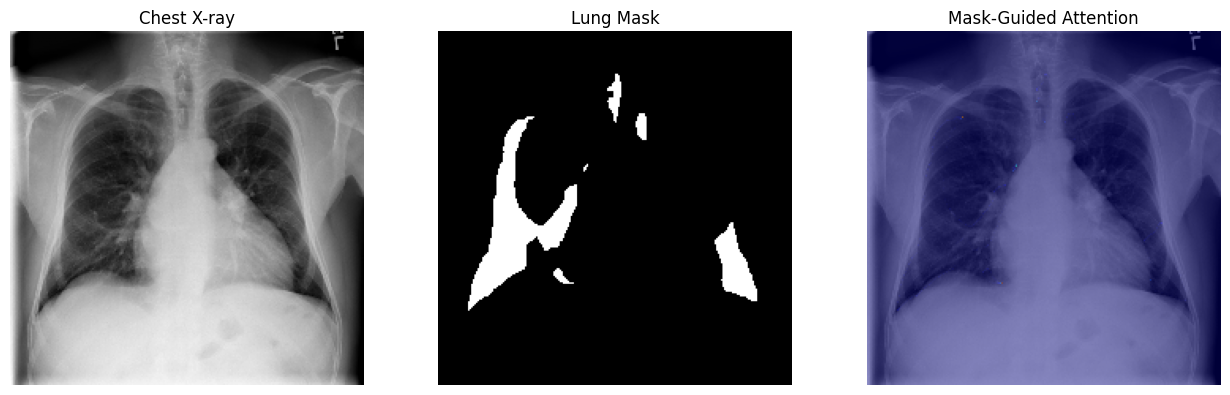

In [22]:
# ==========================================================
# Stage 5 – Step 4.4 : Visualize Mask-Guided Attention
# ==========================================================

plt.figure(figsize=(13, 4))

# Chest X-ray
plt.subplot(1, 3, 1)

plt.imshow(
    xai_result["image"],
    cmap="gray"
)

plt.title("Chest X-ray")
plt.axis("off")


# Lung Mask
plt.subplot(1, 3, 2)

plt.imshow(
    xai_result["mask"],
    cmap="gray"
)

plt.title("Lung Mask")
plt.axis("off")


# Attention overlay
plt.subplot(1, 3, 3)

plt.imshow(
    xai_result["image"],
    cmap="gray"
)

plt.imshow(
    xai_result["attention_map"],
    cmap="jet",
    alpha=0.45
)

plt.title("Mask-Guided Attention")
plt.axis("off")


plt.tight_layout()
plt.show()

In [23]:
# ==========================================================
# Stage 5 – Step 5.1 : Grad-CAM Class
# ==========================================================

class GradCAM:

    def __init__(self, model, target_layer):

        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None

        # Hook feature maps
        self.forward_handle = target_layer.register_forward_hook(
            self._save_activations
        )

        # Hook gradients
        self.backward_handle = target_layer.register_full_backward_hook(
            self._save_gradients
        )


    def _save_activations(self, module, input, output):

        self.activations = output


    def _save_gradients(self, module, grad_input, grad_output):

        self.gradients = grad_output[0]


    def generate(self, input_tensor, class_index):

        self.model.eval()

        # Clear old gradients
        self.model.zero_grad(set_to_none=True)

        # Forward pass
        logits, fusion_weights, attention_map = self.model(
            input_tensor
        )

        # Select disease score
        target_score = logits[:, class_index].sum()

        # Backward pass
        target_score.backward()

        # --------------------------------------------------
        # Calculate Grad-CAM weights
        # --------------------------------------------------

        weights = self.gradients.mean(
            dim=(2, 3),
            keepdim=True
        )

        # Weighted sum of activation maps
        cam = (
            weights * self.activations
        ).sum(
            dim=1,
            keepdim=True
        )

        # Keep positive importance only
        cam = F.relu(cam)

        # Resize to input image size
        cam = F.interpolate(
            cam,
            size=input_tensor.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        # --------------------------------------------------
        # Normalize each CAM to 0–1
        # --------------------------------------------------

        B = cam.size(0)

        cam_flat = cam.view(B, -1)

        cam_min = cam_flat.min(
            dim=1
        )[0].view(B, 1, 1, 1)

        cam_max = cam_flat.max(
            dim=1
        )[0].view(B, 1, 1, 1)

        cam = (
            cam - cam_min
        ) / (
            cam_max - cam_min + 1e-8
        )

        return (
            cam.detach(),
            logits.detach(),
            fusion_weights.detach(),
            attention_map.detach()
        )


    def remove_hooks(self):

        self.forward_handle.remove()
        self.backward_handle.remove()


print("✅ Grad-CAM class created successfully.")

✅ Grad-CAM class created successfully.


In [24]:
# ==========================================================
# Stage 5 – Step 5.2 : Attach Grad-CAM
# ==========================================================

target_layer = best_model.cnn_branch.features[-1]

gradcam = GradCAM(
    model=best_model,
    target_layer=target_layer
)

print("=" * 70)
print("Grad-CAM Initialized")
print("=" * 70)

print("Target Layer:")
print(target_layer)

Grad-CAM Initialized
Target Layer:
Conv2dNormActivation(
  (0): Conv2d(320, 1280, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (1): BatchNorm2d(1280, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): SiLU(inplace=True)
)


In [25]:
# ==========================================================
# Stage 5 – Step 5.3 : Select Disease for Grad-CAM
# ==========================================================

target_disease = "Cardiomegaly"

target_class = DISEASES.index(
    target_disease
)

sample_row = representative_cases[
    target_disease
]

xai_result = analyze_xai_case(
    model=best_model,
    image_path=sample_row["image_path"],
    mask_path=sample_row["mask_path"],
    thresholds=optimal_thresholds,
    device=device
)

input_tensor = xai_result[
    "input_tensor"
]

print("=" * 70)
print("Grad-CAM Target")
print("=" * 70)

print("Image   :", sample_row["Image Index"])
print("Disease :", target_disease)
print("Class   :", target_class)

Grad-CAM Target
Image   : 00000001_000.png
Disease : Cardiomegaly
Class   : 1


In [26]:
# ==========================================================
# Stage 5 – Step 5.4 : Generate Disease-Specific Grad-CAM
# ==========================================================

cam, logits, fusion_weights, attention_map = gradcam.generate(
    input_tensor,
    target_class
)

probabilities = torch.sigmoid(
    logits
)

target_probability = probabilities[
    0,
    target_class
].item()

cam_np = (
    cam[0, 0]
    .cpu()
    .numpy()
)

print("=" * 70)
print("Grad-CAM Generated")
print("=" * 70)

print("Disease     :", target_disease)
print(
    "Probability :",
    f"{target_probability:.4f}"
)

print(
    "CAM Shape   :",
    cam.shape
)

print(
    "CAM Range   :",
    f"{cam.min().item():.4f}",
    "to",
    f"{cam.max().item():.4f}"
)

Grad-CAM Generated
Disease     : Cardiomegaly
Probability : 0.9961
CAM Shape   : torch.Size([1, 1, 224, 224])
CAM Range   : 0.0000 to 1.0000


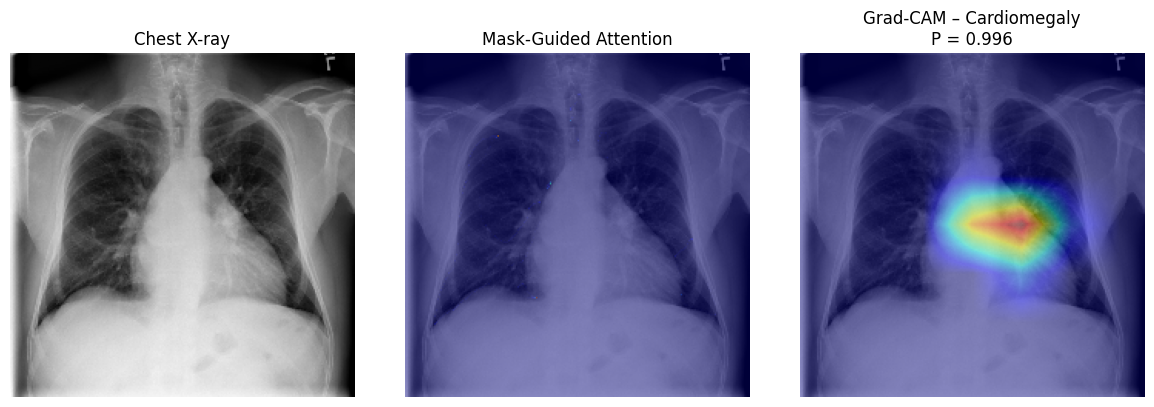

In [27]:
# ==========================================================
# Stage 5 – Step 5.5 : Visualize Grad-CAM
# ==========================================================

plt.figure(figsize=(12, 4))

# Original X-ray
plt.subplot(1, 3, 1)

plt.imshow(
    xai_result["image"],
    cmap="gray"
)

plt.title("Chest X-ray")
plt.axis("off")


# Mask-guided attention
plt.subplot(1, 3, 2)

plt.imshow(
    xai_result["image"],
    cmap="gray"
)

plt.imshow(
    xai_result["attention_map"],
    cmap="jet",
    alpha=0.45
)

plt.title("Mask-Guided Attention")
plt.axis("off")


# Disease-specific Grad-CAM
plt.subplot(1, 3, 3)

plt.imshow(
    xai_result["image"],
    cmap="gray"
)

plt.imshow(
    cam_np,
    cmap="jet",
    alpha=0.45
)

plt.title(
    f"Grad-CAM – {target_disease}\n"
    f"P = {target_probability:.3f}"
)

plt.axis("off")

plt.tight_layout()
plt.show()

In [28]:
# ==========================================================
# Stage 5 – Step 6.1 : Multi-Disease Grad-CAM Generation
# ==========================================================

selected_diseases = [
    "Atelectasis",
    "Cardiomegaly",
    "Effusion",
    "Mass",
    "Pneumonia",
    "Pneumothorax"
]

multi_xai_results = {}

for disease in selected_diseases:

    if disease not in representative_cases:
        print(f"Skipping {disease} - no representative case found.")
        continue

    sample_row = representative_cases[disease]

    # Prepare input and standard XAI outputs
    xai_result = analyze_xai_case(
        model=best_model,
        image_path=sample_row["image_path"],
        mask_path=sample_row["mask_path"],
        thresholds=optimal_thresholds,
        device=device
    )

    input_tensor = xai_result["input_tensor"]

    target_class = DISEASES.index(disease)

    # Generate Grad-CAM
    cam, logits, fusion_weights, attention_map = gradcam.generate(
        input_tensor,
        target_class
    )

    probabilities = torch.sigmoid(logits)

    target_probability = probabilities[
        0,
        target_class
    ].item()

    cam_np = (
        cam[0, 0]
        .detach()
        .cpu()
        .numpy()
    )

    multi_xai_results[disease] = {
        "image": xai_result["image"],
        "mask": xai_result["mask"],
        "attention": xai_result["attention_map"],
        "gradcam": cam_np,
        "probability": target_probability,
        "ground_truth": sample_row["Finding Labels"],
        "image_name": sample_row["Image Index"],
        "fusion_weights": fusion_weights[0].cpu().numpy()
    }

print("=" * 70)
print("Multi-Disease Grad-CAM Generation Completed")
print("=" * 70)

print("Generated cases:", len(multi_xai_results))

libpng warning: iCCP: profile 'ICC Profile': 'GRAY': Gray color space not permitted on RGB PNG


Multi-Disease Grad-CAM Generation Completed
Generated cases: 6


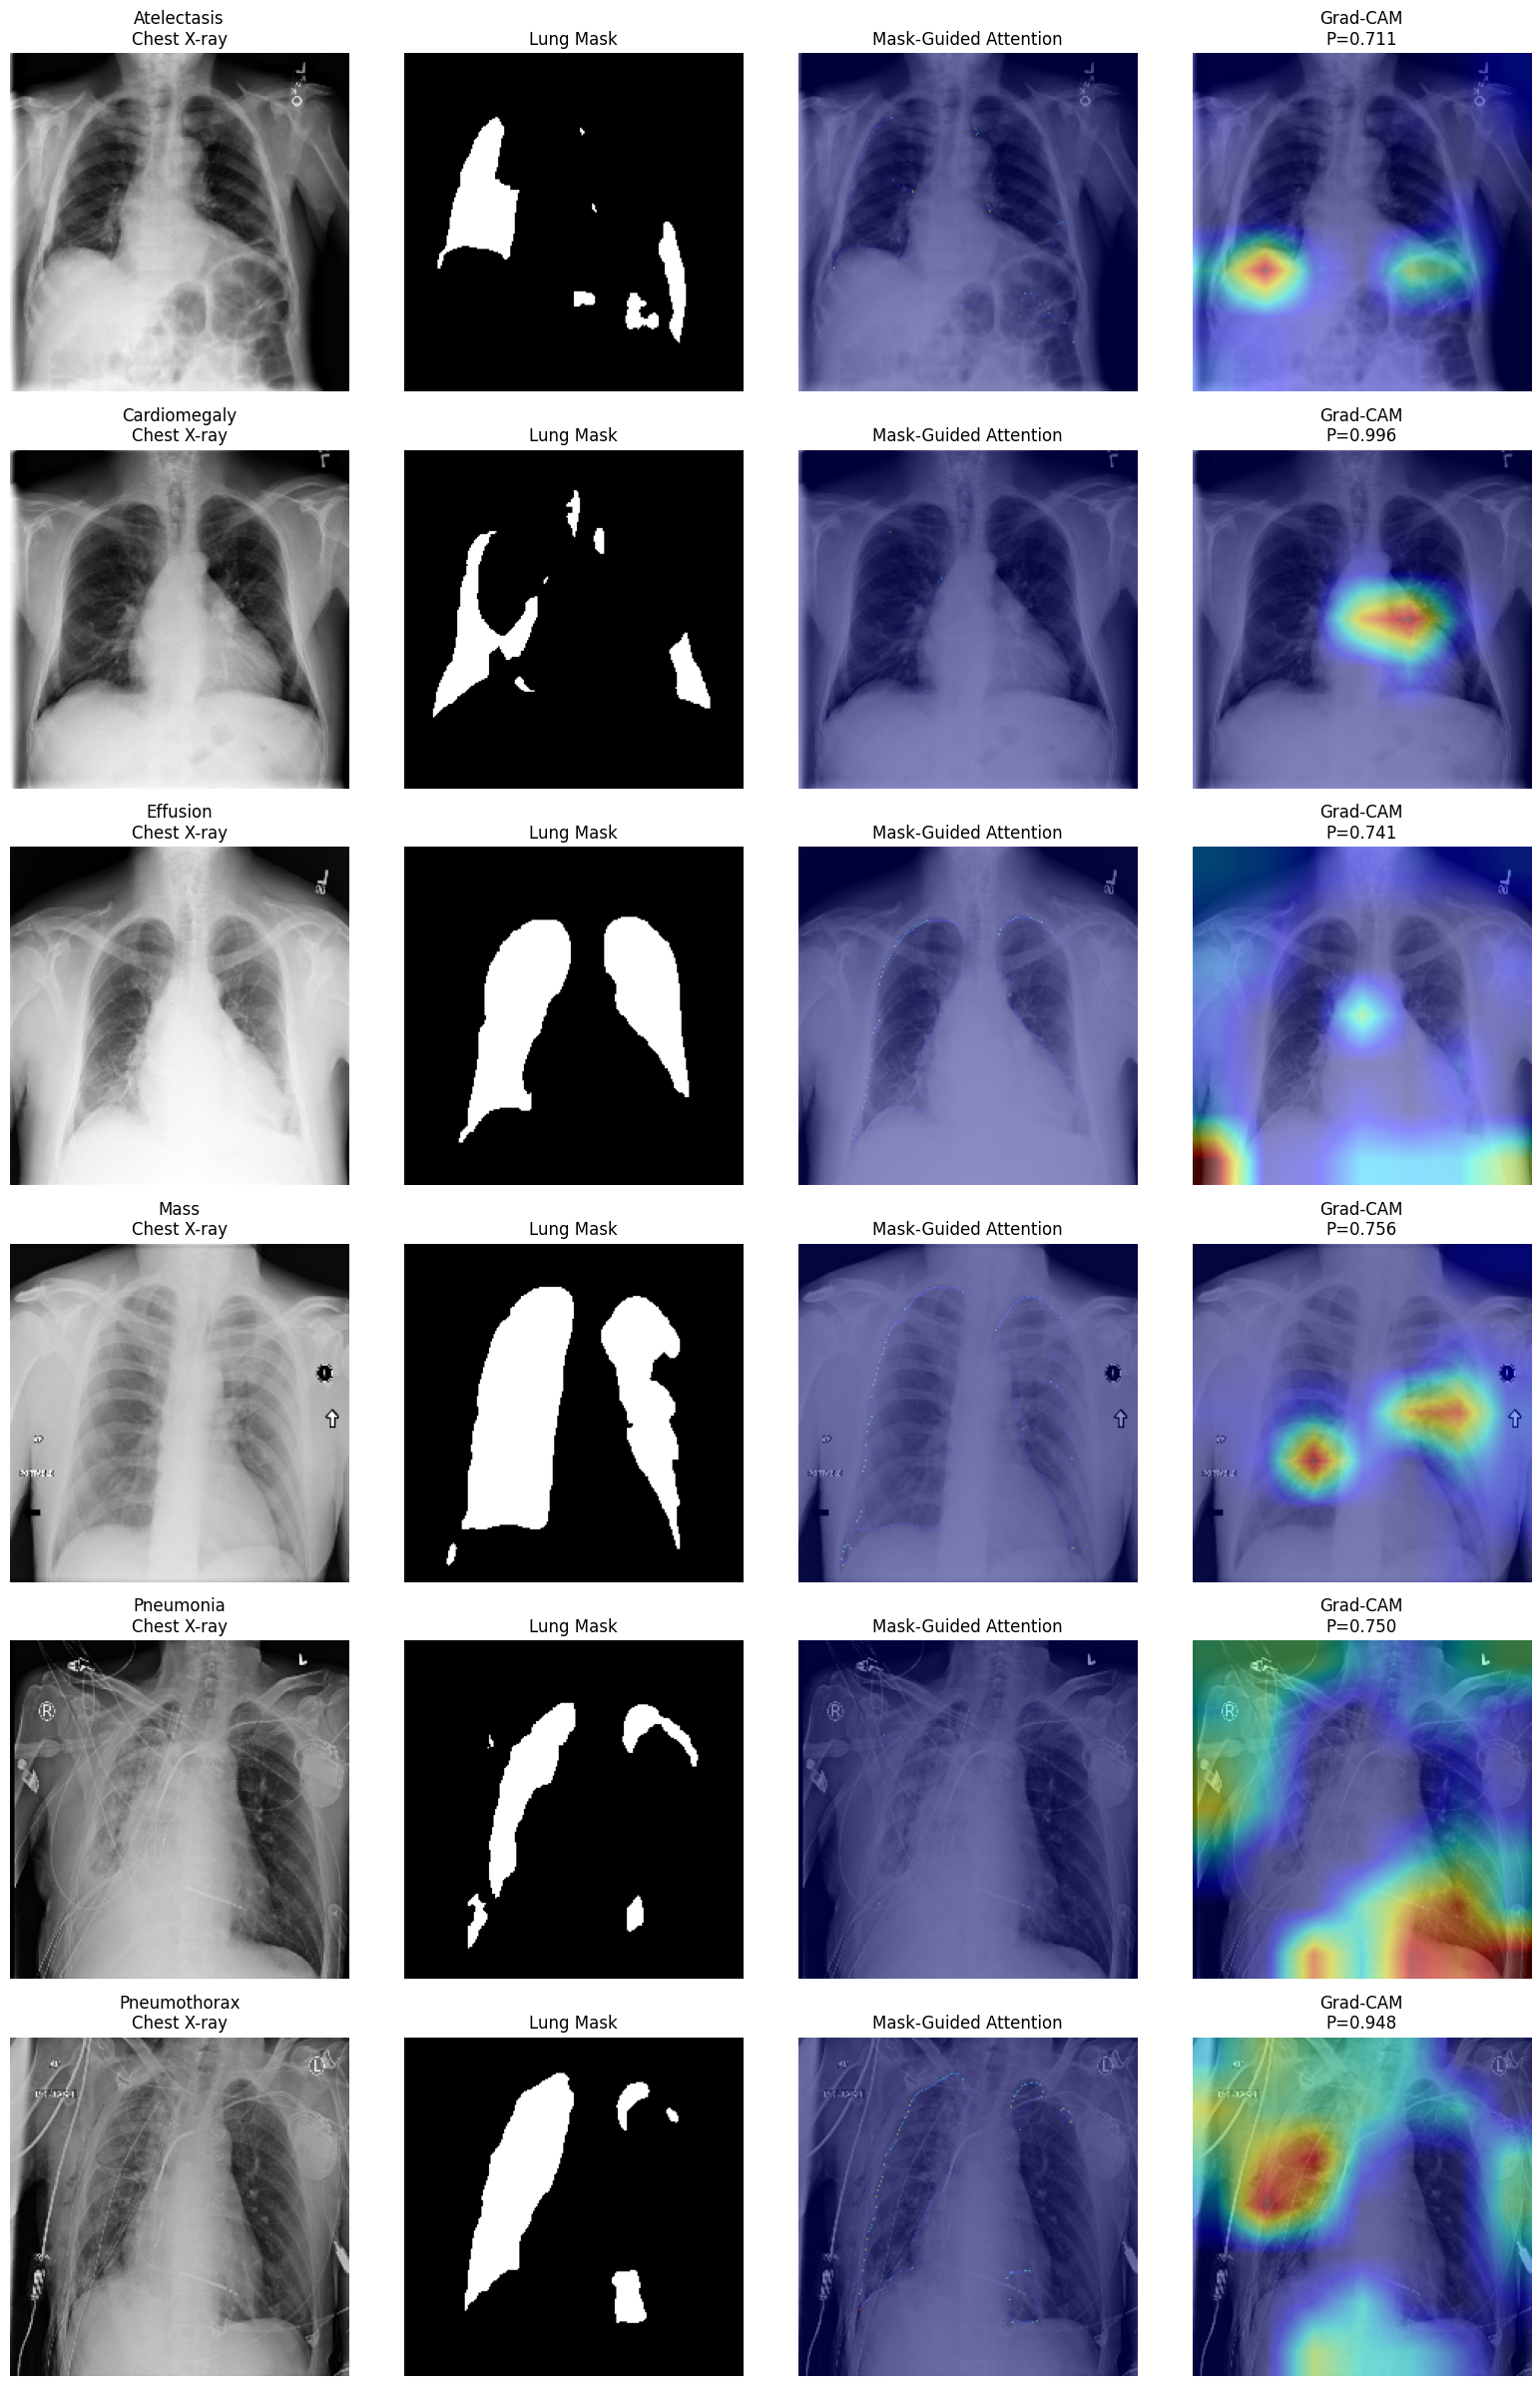

In [29]:
# ==========================================================
# Stage 5 – Step 6.2 : Visualize Multi-Disease XAI Results
# ==========================================================

num_cases = len(multi_xai_results)

plt.figure(figsize=(16, 4 * num_cases))

for row_idx, (disease, result) in enumerate(
    multi_xai_results.items()
):

    # Chest X-ray
    plt.subplot(
        num_cases,
        4,
        row_idx * 4 + 1
    )

    plt.imshow(
        result["image"],
        cmap="gray"
    )

    plt.title(
        f"{disease}\nChest X-ray"
    )

    plt.axis("off")

    # Lung mask
    plt.subplot(
        num_cases,
        4,
        row_idx * 4 + 2
    )

    plt.imshow(
        result["mask"],
        cmap="gray"
    )

    plt.title("Lung Mask")
    plt.axis("off")

    # Mask-guided attention
    plt.subplot(
        num_cases,
        4,
        row_idx * 4 + 3
    )

    plt.imshow(
        result["image"],
        cmap="gray"
    )

    plt.imshow(
        result["attention"],
        cmap="jet",
        alpha=0.45
    )

    plt.title("Mask-Guided Attention")
    plt.axis("off")

    # Grad-CAM
    plt.subplot(
        num_cases,
        4,
        row_idx * 4 + 4
    )

    plt.imshow(
        result["image"],
        cmap="gray"
    )

    plt.imshow(
        result["gradcam"],
        cmap="jet",
        alpha=0.45
    )

    plt.title(
        f"Grad-CAM\nP={result['probability']:.3f}"
    )

    plt.axis("off")


plt.tight_layout()
plt.show()

In [30]:
# ==========================================================
# Stage 5 – Step 6.3 : Save Individual XAI Figures
# ==========================================================

for disease, result in multi_xai_results.items():

    save_path = (
        xai_dir /
        f"xai_{disease}.png"
    )

    plt.figure(figsize=(12, 4))

    # Original
    plt.subplot(1, 3, 1)

    plt.imshow(
        result["image"],
        cmap="gray"
    )

    plt.title("Chest X-ray")
    plt.axis("off")

    # Attention
    plt.subplot(1, 3, 2)

    plt.imshow(
        result["image"],
        cmap="gray"
    )

    plt.imshow(
        result["attention"],
        cmap="jet",
        alpha=0.45
    )

    plt.title("Mask-Guided Attention")
    plt.axis("off")

    # Grad-CAM
    plt.subplot(1, 3, 3)

    plt.imshow(
        result["image"],
        cmap="gray"
    )

    plt.imshow(
        result["gradcam"],
        cmap="jet",
        alpha=0.45
    )

    plt.title(
        f"{disease}\n"
        f"P={result['probability']:.3f}"
    )

    plt.axis("off")

    plt.tight_layout()

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

    print("Saved:", save_path)

Saved: /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/figures/xai/xai_Atelectasis.png
Saved: /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/figures/xai/xai_Cardiomegaly.png
Saved: /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/figures/xai/xai_Effusion.png
Saved: /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/figures/xai/xai_Mass.png
Saved: /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/figures/xai/xai_Pneumonia.png
Saved: /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/figures/xai/xai_Pneumothorax.png


In [32]:
# ==========================================================
# Stage 5 – Step 6.4 : Save XAI Summary Table
# ==========================================================

xai_summary_rows = []

for disease, result in multi_xai_results.items():

    xai_summary_rows.append({

        "Disease": disease,

        "Image": result["image_name"],

        "Ground Truth":
            result["ground_truth"],

        "Prediction Probability":
            result["probability"],

        "CNN Fusion Weight":
            result["fusion_weights"][0],

        "MaxViT Fusion Weight":
            result["fusion_weights"][1]
    })


xai_summary_df = pd.DataFrame(
    xai_summary_rows
)

xai_summary_path = (
    results_dir /
    "tables" /
    "xai_summary.csv"
)

xai_summary_df.to_csv(
    xai_summary_path,
    index=False
)

display(
    xai_summary_df.round(4)
)

print("\nSaved to:")
print(xai_summary_path)

,Disease,Image,Ground Truth,Prediction Probability,CNN Fusion Weight,MaxViT Fusion Weight
0,Atelectasis,00000011_006.png,Atelectasis,0.7107,1.0,0.0
1,Cardiomegaly,00000001_000.png,Cardiomegaly,0.9961,1.0,0.0
2,Effusion,00000001_002.png,Cardiomegaly|Effusion,0.7415,1.0,0.0
3,Mass,00000004_000.png,Mass|Nodule,0.7555,1.0,0.0
4,Pneumonia,00000013_010.png,Effusion|Pneumonia|Pneumothorax,0.7502,1.0,0.0
5,Pneumothorax,00000013_001.png,Emphysema|Pneumothorax,0.9478,1.0,0.0



Saved to:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/tables/xai_summary.csv


In [33]:
# ==========================================================
# Stage 5 – Step 7.1 : Fusion Weight Analysis
# ==========================================================

fusion_analysis_rows = []

for disease, result in multi_xai_results.items():

    cnn_weight = float(
        result["fusion_weights"][0]
    )

    maxvit_weight = float(
        result["fusion_weights"][1]
    )

    dominant_branch = (
        "EfficientNet-B0"
        if cnn_weight > maxvit_weight
        else "MaxViT"
    )

    fusion_analysis_rows.append({
        "Disease": disease,
        "CNN Weight": cnn_weight,
        "MaxViT Weight": maxvit_weight,
        "Dominant Branch": dominant_branch
    })


fusion_analysis_df = pd.DataFrame(
    fusion_analysis_rows
)

display(
    fusion_analysis_df.round(4)
)

,Disease,CNN Weight,MaxViT Weight,Dominant Branch
0,Atelectasis,1.0,0.0,EfficientNet-B0
1,Cardiomegaly,1.0,0.0,EfficientNet-B0
2,Effusion,1.0,0.0,EfficientNet-B0
3,Mass,1.0,0.0,EfficientNet-B0
4,Pneumonia,1.0,0.0,EfficientNet-B0
5,Pneumothorax,1.0,0.0,EfficientNet-B0


In [34]:
# ==========================================================
# Stage 5 – Step 7.2 : Verify Fusion Weights
# ==========================================================

fusion_analysis_df["Weight Sum"] = (
    fusion_analysis_df["CNN Weight"]
    +
    fusion_analysis_df["MaxViT Weight"]
)

print("=" * 70)
print("Fusion Weight Verification")
print("=" * 70)

display(
    fusion_analysis_df[
        [
            "Disease",
            "CNN Weight",
            "MaxViT Weight",
            "Weight Sum"
        ]
    ].round(4)
)

print(
    "\nAverage Weight Sum:",
    fusion_analysis_df["Weight Sum"].mean()
)

Fusion Weight Verification


,Disease,CNN Weight,MaxViT Weight,Weight Sum
0,Atelectasis,1.0,0.0,1.0
1,Cardiomegaly,1.0,0.0,1.0
2,Effusion,1.0,0.0,1.0
3,Mass,1.0,0.0,1.0
4,Pneumonia,1.0,0.0,1.0
5,Pneumothorax,1.0,0.0,1.0



Average Weight Sum: 1.000000000000741


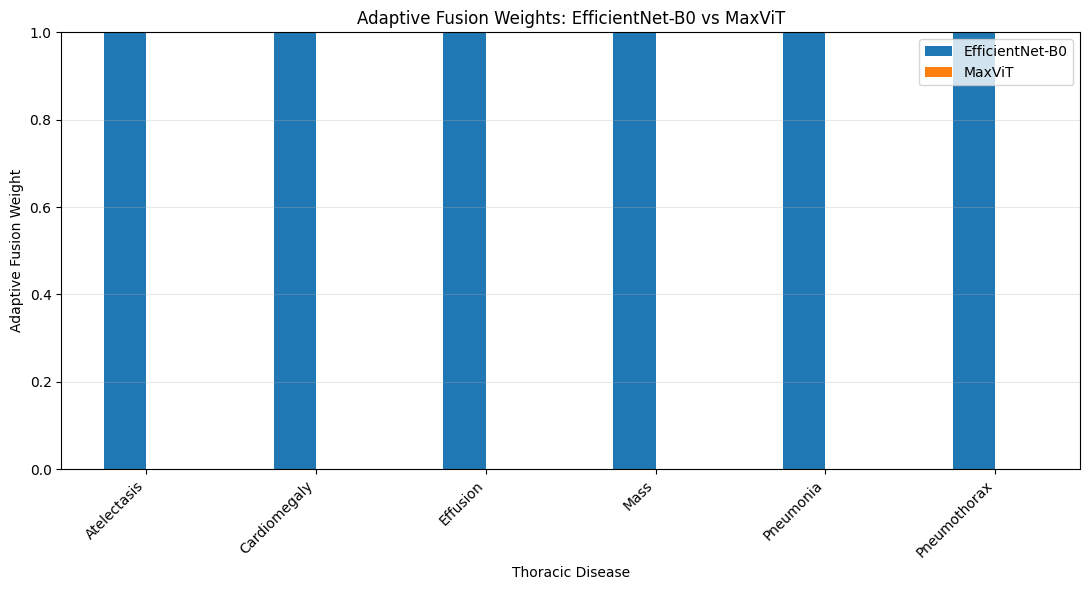

In [35]:
# ==========================================================
# Stage 5 – Step 7.3 : Fusion Weight Visualization
# ==========================================================

plot_df = fusion_analysis_df.set_index(
    "Disease"
)[
    [
        "CNN Weight",
        "MaxViT Weight"
    ]
]

ax = plot_df.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.ylabel(
    "Adaptive Fusion Weight"
)

plt.xlabel(
    "Thoracic Disease"
)

plt.title(
    "Adaptive Fusion Weights: EfficientNet-B0 vs MaxViT"
)

plt.ylim(
    0,
    1
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.legend(
    [
        "EfficientNet-B0",
        "MaxViT"
    ]
)

plt.tight_layout()

plt.show()

In [36]:
# ==========================================================
# Stage 5 – Step 7.4 : Average Branch Contribution
# ==========================================================

average_cnn = fusion_analysis_df[
    "CNN Weight"
].mean()

average_maxvit = fusion_analysis_df[
    "MaxViT Weight"
].mean()

print("=" * 70)
print("Average Adaptive Fusion Contribution")
print("=" * 70)

print(
    f"EfficientNet-B0 : {average_cnn:.4f}"
)

print(
    f"MaxViT          : {average_maxvit:.4f}"
)

print()

if average_cnn > average_maxvit:

    print(
        "Overall dominant branch: EfficientNet-B0"
    )

elif average_maxvit > average_cnn:

    print(
        "Overall dominant branch: MaxViT"
    )

else:

    print(
        "Both branches contribute equally."
    )

Average Adaptive Fusion Contribution
EfficientNet-B0 : 1.0000
MaxViT          : 0.0000

Overall dominant branch: EfficientNet-B0


In [37]:
# ==========================================================
# Stage 5 – Step 7.5 : Save Fusion Analysis
# ==========================================================

fusion_table_path = (
    results_dir
    / "tables"
    / "adaptive_fusion_analysis.csv"
)

fusion_analysis_df.to_csv(
    fusion_table_path,
    index=False
)

print(
    "Fusion analysis saved to:"
)

print(
    fusion_table_path
)

Fusion analysis saved to:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/tables/adaptive_fusion_analysis.csv


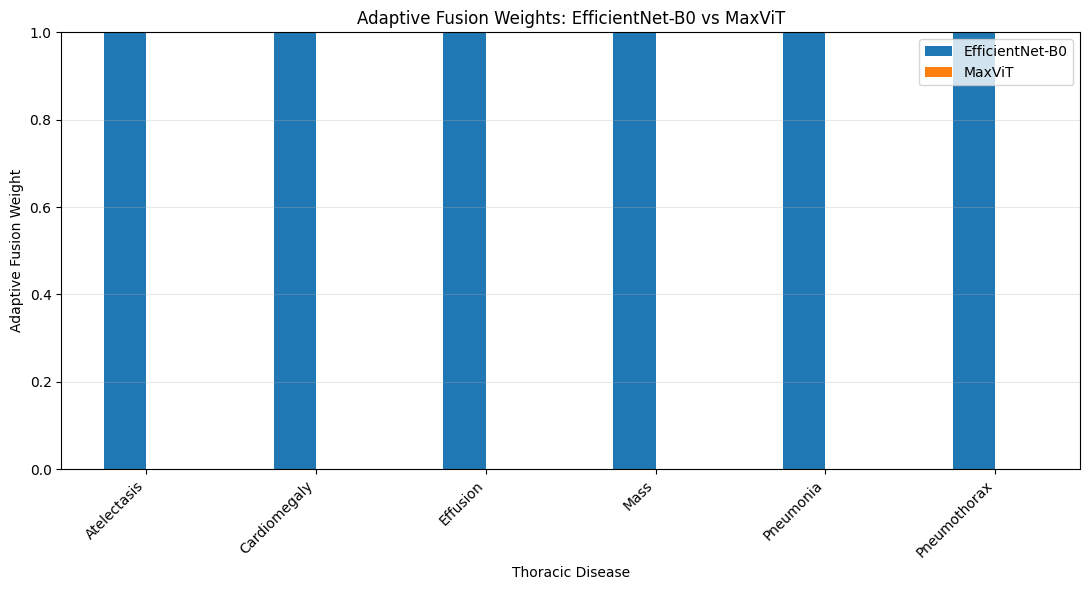

Figure saved to:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/figures/xai/adaptive_fusion_weights.png


In [38]:
# ==========================================================
# Stage 5 – Step 7.6 : Save Fusion Weight Figure
# ==========================================================

fusion_figure_path = (
    xai_dir /
    "adaptive_fusion_weights.png"
)

ax = plot_df.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.ylabel(
    "Adaptive Fusion Weight"
)

plt.xlabel(
    "Thoracic Disease"
)

plt.title(
    "Adaptive Fusion Weights: EfficientNet-B0 vs MaxViT"
)

plt.ylim(0, 1)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.legend(
    [
        "EfficientNet-B0",
        "MaxViT"
    ]
)

plt.tight_layout()

plt.savefig(
    fusion_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Figure saved to:"
)

print(
    fusion_figure_path
)

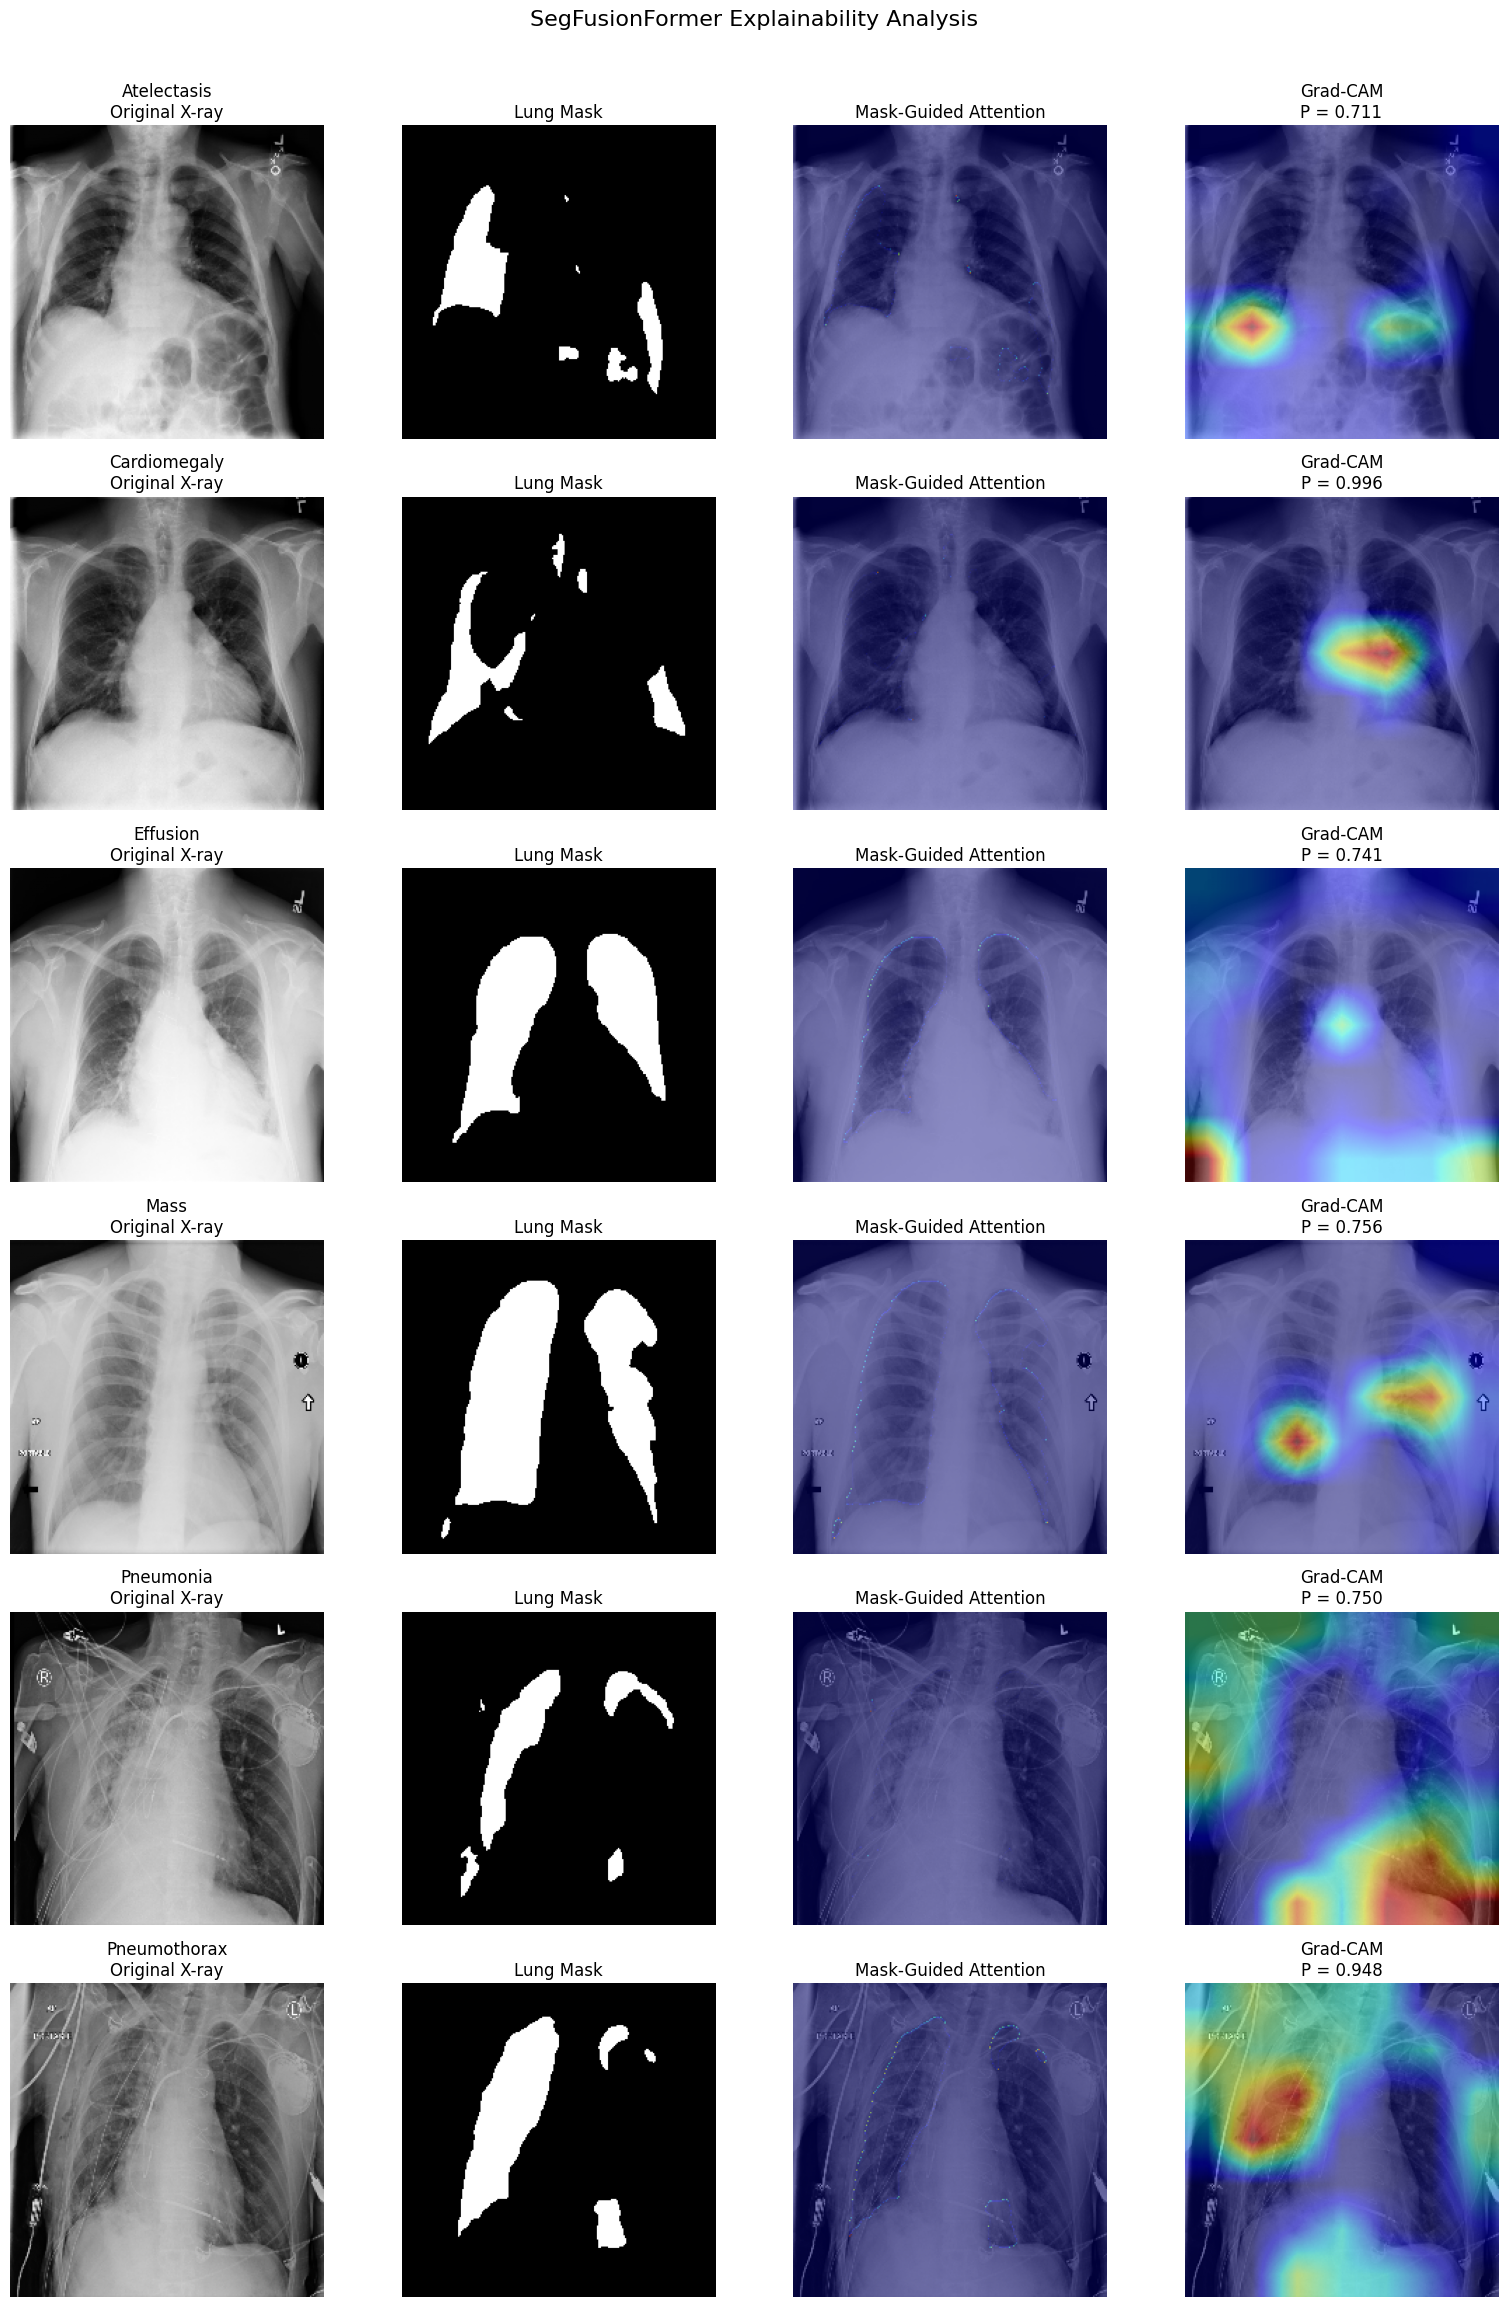

In [39]:
# ==========================================================
# Stage 5 – Step 8.1 : Final Multi-Disease XAI Comparison
# ==========================================================

selected_for_comparison = [
    "Atelectasis",
    "Cardiomegaly",
    "Effusion",
    "Mass",
    "Pneumonia",
    "Pneumothorax"
]

available_cases = [
    disease
    for disease in selected_for_comparison
    if disease in multi_xai_results
]

num_cases = len(available_cases)

fig, axes = plt.subplots(
    num_cases,
    4,
    figsize=(16, 3.8 * num_cases)
)

# If only one row exists, make axes 2D
if num_cases == 1:
    axes = np.expand_dims(axes, axis=0)

for row_idx, disease in enumerate(available_cases):

    result = multi_xai_results[disease]

    image = result["image"]
    mask = result["mask"]
    attention = result["attention"]
    gradcam_map = result["gradcam"]
    probability = result["probability"]

    # --------------------------------------------------
    # Column 1 - Original X-ray
    # --------------------------------------------------

    axes[row_idx, 0].imshow(
        image,
        cmap="gray"
    )

    axes[row_idx, 0].set_title(
        f"{disease}\nOriginal X-ray"
    )

    axes[row_idx, 0].axis("off")

    # --------------------------------------------------
    # Column 2 - Lung Mask
    # --------------------------------------------------

    axes[row_idx, 1].imshow(
        mask,
        cmap="gray"
    )

    axes[row_idx, 1].set_title(
        "Lung Mask"
    )

    axes[row_idx, 1].axis("off")

    # --------------------------------------------------
    # Column 3 - Mask-Guided Attention
    # --------------------------------------------------

    axes[row_idx, 2].imshow(
        image,
        cmap="gray"
    )

    axes[row_idx, 2].imshow(
        attention,
        cmap="jet",
        alpha=0.45
    )

    axes[row_idx, 2].set_title(
        "Mask-Guided Attention"
    )

    axes[row_idx, 2].axis("off")

    # --------------------------------------------------
    # Column 4 - Grad-CAM
    # --------------------------------------------------

    axes[row_idx, 3].imshow(
        image,
        cmap="gray"
    )

    axes[row_idx, 3].imshow(
        gradcam_map,
        cmap="jet",
        alpha=0.45
    )

    axes[row_idx, 3].set_title(
        f"Grad-CAM\nP = {probability:.3f}"
    )

    axes[row_idx, 3].axis("off")


plt.suptitle(
    "SegFusionFormer Explainability Analysis",
    fontsize=16,
    y=1.01
)

plt.tight_layout()

plt.show()

In [40]:
# ==========================================================
# Stage 5 – Step 8.2 : Save Final XAI Comparison Figure
# ==========================================================

final_xai_comparison_path = (
    xai_dir /
    "segfusionformer_final_xai_comparison.png"
)

fig.savefig(
    final_xai_comparison_path,
    dpi=300,
    bbox_inches="tight"
)

print("=" * 70)
print("Final XAI Comparison Saved")
print("=" * 70)

print(final_xai_comparison_path)

Final XAI Comparison Saved
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/figures/xai/segfusionformer_final_xai_comparison.png


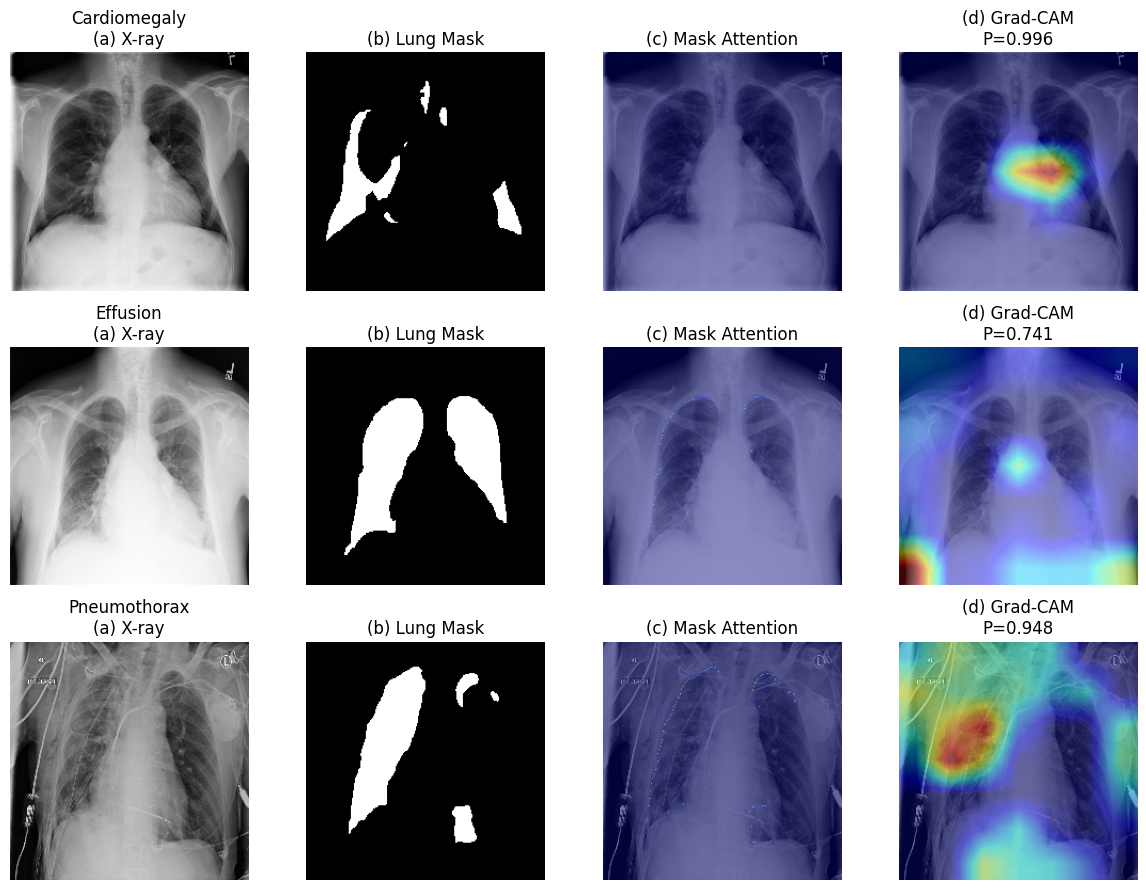

Saved:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/figures/xai/segfusionformer_ieee_xai_figure.png


In [41]:
# ==========================================================
# Stage 5 – Step 8.3 : Compact IEEE-Style XAI Figure
# ==========================================================

paper_diseases = [
    "Cardiomegaly",
    "Effusion",
    "Pneumothorax"
]

paper_cases = [
    d for d in paper_diseases
    if d in multi_xai_results
]

fig_paper, axes = plt.subplots(
    len(paper_cases),
    4,
    figsize=(12, 3 * len(paper_cases))
)

if len(paper_cases) == 1:
    axes = np.expand_dims(axes, axis=0)

for row_idx, disease in enumerate(paper_cases):

    result = multi_xai_results[disease]

    image = result["image"]

    axes[row_idx, 0].imshow(
        image,
        cmap="gray"
    )
    axes[row_idx, 0].set_title(
        f"{disease}\n(a) X-ray"
    )

    axes[row_idx, 1].imshow(
        result["mask"],
        cmap="gray"
    )
    axes[row_idx, 1].set_title(
        "(b) Lung Mask"
    )

    axes[row_idx, 2].imshow(
        image,
        cmap="gray"
    )
    axes[row_idx, 2].imshow(
        result["attention"],
        cmap="jet",
        alpha=0.45
    )
    axes[row_idx, 2].set_title(
        "(c) Mask Attention"
    )

    axes[row_idx, 3].imshow(
        image,
        cmap="gray"
    )
    axes[row_idx, 3].imshow(
        result["gradcam"],
        cmap="jet",
        alpha=0.45
    )
    axes[row_idx, 3].set_title(
        f"(d) Grad-CAM\nP={result['probability']:.3f}"
    )

    for col in range(4):
        axes[row_idx, col].axis("off")

plt.tight_layout()

paper_figure_path = (
    xai_dir /
    "segfusionformer_ieee_xai_figure.png"
)

plt.savefig(
    paper_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(paper_figure_path)

In [43]:
# ==========================================================
# Stage 5 – Helper : DiseaseClassificationDataset
# ==========================================================

from torch.utils.data import Dataset, DataLoader

IMG_SIZE = 224


class DiseaseClassificationDataset(Dataset):

    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image = cv2.imread(
            str(row["image_path"]),
            cv2.IMREAD_GRAYSCALE
        )

        mask = cv2.imread(
            str(row["mask_path"]),
            cv2.IMREAD_GRAYSCALE
        )

        image = cv2.resize(
            image,
            (IMG_SIZE, IMG_SIZE)
        )

        mask = cv2.resize(
            mask,
            (IMG_SIZE, IMG_SIZE),
            interpolation=cv2.INTER_NEAREST
        )

        image = image.astype(np.float32) / 255.0
        mask = mask.astype(np.float32) / 255.0

        mask = (mask > 0.5).astype(np.float32)

        image = torch.from_numpy(image).unsqueeze(0)
        mask = torch.from_numpy(mask).unsqueeze(0)

        x = torch.cat(
            [image, mask],
            dim=0
        )

        y = torch.tensor(
            row[DISEASES].values.astype(np.float32)
        )

        return x, y


print("✅ DiseaseClassificationDataset recreated.")

✅ DiseaseClassificationDataset recreated.


In [45]:
# ==========================================================
# Stage 5 – Helper : Recreate Validation Split
# ==========================================================

from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("Training Samples   :", len(train_df))
print("Validation Samples :", len(val_df))

Training Samples   : 89696
Validation Samples : 22424


In [46]:
# ==========================================================
# Stage 5 – Helper : Validation DataLoader
# ==========================================================

val_dataset = DiseaseClassificationDataset(
    val_df
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

print("=" * 70)
print("Validation DataLoader Created")
print("=" * 70)

print("Validation Samples :", len(val_dataset))
print("Validation Batches :", len(val_loader))
print("Batch Size         :", val_loader.batch_size)

Validation DataLoader Created
Validation Samples : 22424
Validation Batches : 2803
Batch Size         : 8


In [47]:
# ==========================================================
# Stage 5 – Step 9.1 : Validation Predictions for Error Analysis
# ==========================================================

from tqdm.auto import tqdm

all_labels = []
all_probs = []
all_inputs = []

best_model.eval()

with torch.no_grad():

    for inputs, labels in tqdm(
        val_loader,
        desc="Collecting Validation Predictions"
    ):

        inputs = inputs.to(device)

        logits, _, _ = best_model(inputs)

        probs = torch.sigmoid(logits)

        all_labels.append(
            labels.cpu().numpy()
        )

        all_probs.append(
            probs.cpu().numpy()
        )

        all_inputs.append(
            inputs.cpu().numpy()
        )

y_true_xai = np.concatenate(
    all_labels,
    axis=0
)

y_prob_xai = np.concatenate(
    all_probs,
    axis=0
)

x_val_xai = np.concatenate(
    all_inputs,
    axis=0
)

# Apply optimized thresholds
y_pred_xai = np.zeros_like(
    y_prob_xai,
    dtype=int
)

for i in range(len(DISEASES)):

    y_pred_xai[:, i] = (
        y_prob_xai[:, i]
        >= optimal_thresholds[i]
    ).astype(int)

print("=" * 70)
print("Validation Predictions Ready")
print("=" * 70)

print("Samples :", len(y_true_xai))
print("Classes :", y_true_xai.shape[1])

Validation Predictions Ready
Samples : 22424
Classes : 14


In [48]:
# ==========================================================
# Stage 5 – Step 9.2 : Identify TP / FP / FN Cases
# ==========================================================

error_analysis = {}

for class_idx, disease in enumerate(DISEASES):

    true_labels = y_true_xai[:, class_idx]
    predictions = y_pred_xai[:, class_idx]

    tp_indices = np.where(
        (true_labels == 1) &
        (predictions == 1)
    )[0]

    fp_indices = np.where(
        (true_labels == 0) &
        (predictions == 1)
    )[0]

    fn_indices = np.where(
        (true_labels == 1) &
        (predictions == 0)
    )[0]

    error_analysis[disease] = {
        "TP": tp_indices,
        "FP": fp_indices,
        "FN": fn_indices
    }


print("=" * 70)
print("Prediction Error Analysis")
print("=" * 70)

for disease in DISEASES:

    print(
        f"{disease:20s} | "
        f"TP={len(error_analysis[disease]['TP']):5d} | "
        f"FP={len(error_analysis[disease]['FP']):5d} | "
        f"FN={len(error_analysis[disease]['FN']):5d}"
    )

Prediction Error Analysis
Atelectasis          | TP= 1125 | FP= 2936 | FN= 1100
Cardiomegaly         | TP=  236 | FP=  486 | FN=  321
Effusion             | TP= 1652 | FP= 2290 | FN=  973
Infiltration         | TP= 2163 | FP= 4717 | FN= 1788
Mass                 | TP=  442 | FP=  760 | FN=  699
Nodule               | TP=  313 | FP= 1090 | FN=  972
Pneumonia            | TP=   83 | FP= 1637 | FN=  211
Pneumothorax         | TP=  510 | FP=  909 | FN=  536
Consolidation        | TP=  386 | FP= 2456 | FN=  508
Edema                | TP=  139 | FP=  488 | FN=  307
Emphysema            | TP=  247 | FP=  411 | FN=  240
Fibrosis             | TP=  104 | FP=  985 | FN=  215
Pleural_Thickening   | TP=  266 | FP= 1478 | FN=  397
Hernia               | TP=   23 | FP=   21 | FN=   23


In [49]:
# ==========================================================
# Stage 5 – Step 9.3 : Error Analysis Summary Table
# ==========================================================

error_rows = []

for disease in DISEASES:

    tp = len(
        error_analysis[disease]["TP"]
    )

    fp = len(
        error_analysis[disease]["FP"]
    )

    fn = len(
        error_analysis[disease]["FN"]
    )

    error_rows.append({
        "Disease": disease,
        "True Positives": tp,
        "False Positives": fp,
        "False Negatives": fn
    })


error_df = pd.DataFrame(
    error_rows
)

display(
    error_df
)

,Disease,True Positives,False Positives,False Negatives
0,Atelectasis,1125,2936,1100
1,Cardiomegaly,236,486,321
2,Effusion,1652,2290,973
3,Infiltration,2163,4717,1788
4,Mass,442,760,699
5,Nodule,313,1090,972
6,Pneumonia,83,1637,211
7,Pneumothorax,510,909,536
8,Consolidation,386,2456,508
9,Edema,139,488,307


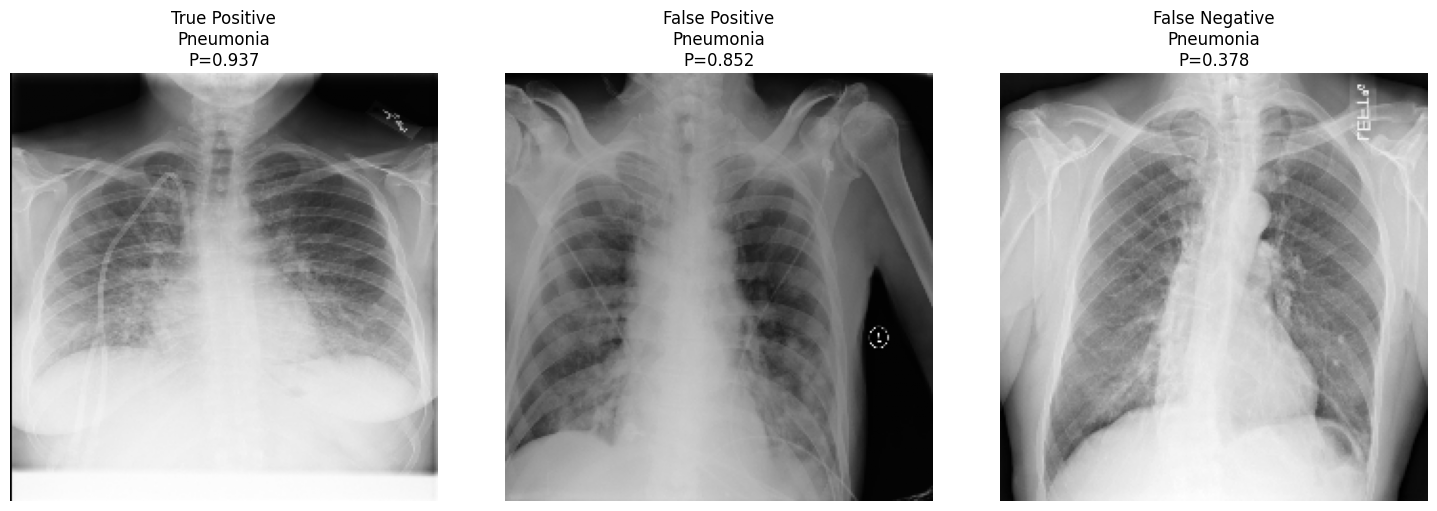

In [50]:
# ==========================================================
# Stage 5 – Step 9.4 : Visualize TP / FP / FN Examples
# ==========================================================

analysis_disease = "Pneumonia"

class_idx = DISEASES.index(
    analysis_disease
)

cases = error_analysis[
    analysis_disease
]

selected_cases = {}

if len(cases["TP"]) > 0:
    selected_cases["True Positive"] = cases["TP"][0]

if len(cases["FP"]) > 0:
    selected_cases["False Positive"] = cases["FP"][0]

if len(cases["FN"]) > 0:
    selected_cases["False Negative"] = cases["FN"][0]


num_cases = len(selected_cases)

plt.figure(
    figsize=(5 * num_cases, 5)
)

for i, (case_type, idx) in enumerate(
    selected_cases.items()
):

    image = x_val_xai[
        idx,
        0
    ]

    probability = y_prob_xai[
        idx,
        class_idx
    ]

    plt.subplot(
        1,
        num_cases,
        i + 1
    )

    plt.imshow(
        image,
        cmap="gray"
    )

    plt.title(
        f"{case_type}\n"
        f"{analysis_disease}\n"
        f"P={probability:.3f}"
    )

    plt.axis("off")


plt.tight_layout()
plt.show()

In [51]:
# ==========================================================
# Stage 5 – Step 9.5 : Grad-CAM Error Analysis
# ==========================================================

gradcam_case_results = {}

for case_type, idx in selected_cases.items():

    input_tensor = torch.tensor(
        x_val_xai[idx]
    ).unsqueeze(0).float().to(device)

    cam, logits, fusion_weights, attention_map = gradcam.generate(
        input_tensor,
        class_idx
    )

    probability = torch.sigmoid(
        logits
    )[0, class_idx].item()

    gradcam_case_results[
        case_type
    ] = {

        "image":
            x_val_xai[idx, 0],

        "mask":
            x_val_xai[idx, 1],

        "attention":
            attention_map[
                0, 0
            ].cpu().numpy(),

        "gradcam":
            cam[
                0, 0
            ].cpu().numpy(),

        "probability":
            probability
    }


print(
    "✅ Grad-CAM error-analysis cases generated."
)

✅ Grad-CAM error-analysis cases generated.


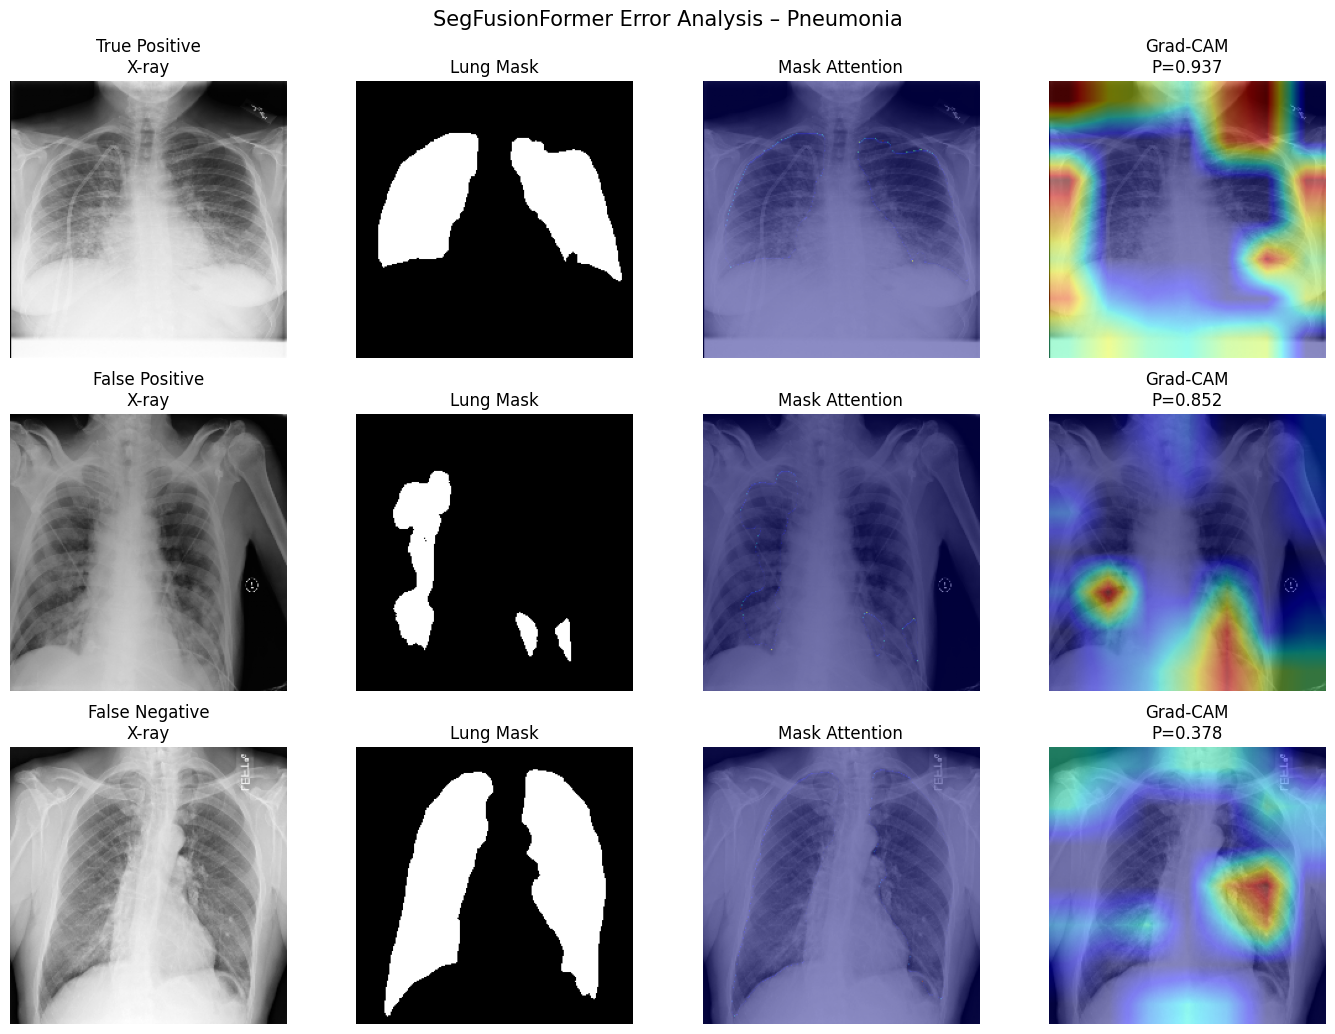

Saved:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/figures/xai/error_analysis_Pneumonia.png


In [52]:
# ==========================================================
# Stage 5 – Step 9.6 : TP / FP / FN XAI Comparison
# ==========================================================

case_names = list(
    gradcam_case_results.keys()
)

num_cases = len(case_names)

fig, axes = plt.subplots(
    num_cases,
    4,
    figsize=(14, 3.5 * num_cases)
)

if num_cases == 1:
    axes = np.expand_dims(
        axes,
        axis=0
    )

for row_idx, case_name in enumerate(
    case_names
):

    result = gradcam_case_results[
        case_name
    ]

    image = result["image"]

    # Original
    axes[row_idx, 0].imshow(
        image,
        cmap="gray"
    )

    axes[row_idx, 0].set_title(
        f"{case_name}\nX-ray"
    )

    # Mask
    axes[row_idx, 1].imshow(
        result["mask"],
        cmap="gray"
    )

    axes[row_idx, 1].set_title(
        "Lung Mask"
    )

    # Attention
    axes[row_idx, 2].imshow(
        image,
        cmap="gray"
    )

    axes[row_idx, 2].imshow(
        result["attention"],
        cmap="jet",
        alpha=0.45
    )

    axes[row_idx, 2].set_title(
        "Mask Attention"
    )

    # Grad-CAM
    axes[row_idx, 3].imshow(
        image,
        cmap="gray"
    )

    axes[row_idx, 3].imshow(
        result["gradcam"],
        cmap="jet",
        alpha=0.45
    )

    axes[row_idx, 3].set_title(
        f"Grad-CAM\n"
        f"P={result['probability']:.3f}"
    )

    for col in range(4):
        axes[row_idx, col].axis(
            "off"
        )


plt.suptitle(
    f"SegFusionFormer Error Analysis – {analysis_disease}",
    fontsize=15
)

plt.tight_layout()

error_figure_path = (
    xai_dir /
    f"error_analysis_{analysis_disease}.png"
)

plt.savefig(
    error_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(error_figure_path)

In [53]:
# ==========================================================
# Stage 5 – Step 9.7 : Save Error Analysis Table
# ==========================================================

error_table_path = (
    results_dir
    / "tables"
    / "xai_error_analysis.csv"
)

error_df.to_csv(
    error_table_path,
    index=False
)

print(
    "Error analysis saved to:"
)

print(
    error_table_path
)

Error analysis saved to:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/tables/xai_error_analysis.csv


In [54]:
# ==========================================================
# Stage 5 – Step 10.1 : Create Final XAI Summary
# ==========================================================

xai_final_rows = []

for disease, result in multi_xai_results.items():

    cnn_weight = float(result["fusion_weights"][0])
    maxvit_weight = float(result["fusion_weights"][1])

    dominant_branch = (
        "EfficientNet-B0"
        if cnn_weight > maxvit_weight
        else "MaxViT"
    )

    xai_final_rows.append({
        "Disease": disease,
        "Image": result["image_name"],
        "Ground Truth": result["ground_truth"],
        "Prediction Probability": result["probability"],
        "CNN Fusion Weight": cnn_weight,
        "MaxViT Fusion Weight": maxvit_weight,
        "Dominant Branch": dominant_branch
    })

xai_final_df = pd.DataFrame(xai_final_rows)

display(
    xai_final_df.round(4)
)

,Disease,Image,Ground Truth,Prediction Probability,CNN Fusion Weight,MaxViT Fusion Weight,Dominant Branch
0,Atelectasis,00000011_006.png,Atelectasis,0.7107,1.0,0.0,EfficientNet-B0
1,Cardiomegaly,00000001_000.png,Cardiomegaly,0.9961,1.0,0.0,EfficientNet-B0
2,Effusion,00000001_002.png,Cardiomegaly|Effusion,0.7415,1.0,0.0,EfficientNet-B0
3,Mass,00000004_000.png,Mass|Nodule,0.7555,1.0,0.0,EfficientNet-B0
4,Pneumonia,00000013_010.png,Effusion|Pneumonia|Pneumothorax,0.7502,1.0,0.0,EfficientNet-B0
5,Pneumothorax,00000013_001.png,Emphysema|Pneumothorax,0.9478,1.0,0.0,EfficientNet-B0


In [55]:
# ==========================================================
# Stage 5 – Step 10.2 : Save XAI Summary CSV
# ==========================================================

xai_final_csv = (
    results_dir
    / "tables"
    / "final_xai_summary.csv"
)

xai_final_df.to_csv(
    xai_final_csv,
    index=False
)

print("=" * 70)
print("Final XAI Summary Saved")
print("=" * 70)

print(xai_final_csv)

Final XAI Summary Saved
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/tables/final_xai_summary.csv


In [56]:
# ==========================================================
# Stage 5 – Step 10.3 : Save Error Analysis
# ==========================================================

error_analysis_path = (
    results_dir
    / "tables"
    / "xai_error_analysis.csv"
)

error_df.to_csv(
    error_analysis_path,
    index=False
)

print("Saved:")
print(error_analysis_path)

Saved:
/Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/tables/xai_error_analysis.csv


In [57]:
# ==========================================================
# Stage 5 – Step 10.4 : Verify XAI Output Files
# ==========================================================

print("=" * 70)
print("XAI Figure Verification")
print("=" * 70)

xai_files = sorted(
    xai_dir.glob("*.png")
)

for file in xai_files:
    print("✅", file.name)

print("\nTotal XAI Figures :", len(xai_files))

XAI Figure Verification
✅ adaptive_fusion_weights.png
✅ error_analysis_Pneumonia.png
✅ segfusionformer_final_xai_comparison.png
✅ segfusionformer_ieee_xai_figure.png
✅ xai_Atelectasis.png
✅ xai_Cardiomegaly.png
✅ xai_Effusion.png
✅ xai_Mass.png
✅ xai_Pneumonia.png
✅ xai_Pneumothorax.png

Total XAI Figures : 10


In [58]:
# ==========================================================
# Stage 5 – Step 10.5 : Stage 5 Completion Report
# ==========================================================

print("=" * 80)
print("STAGE 5 - EXPLAINABLE AI ANALYSIS COMPLETED")
print("=" * 80)

print("\nExplainability Methods")
print("----------------------")
print("✓ Mask-Guided Attention")
print("✓ Grad-CAM")

print("\nHybrid Model Interpretation")
print("---------------------------")
print("✓ EfficientNet-B0 fusion contribution")
print("✓ MaxViT fusion contribution")
print("✓ Adaptive fusion analysis")

print("\nQualitative Analysis")
print("--------------------")
print("✓ Multi-disease Grad-CAM")
print("✓ Lung-mask visualization")
print("✓ Attention overlays")
print("✓ Correct / incorrect prediction analysis")

print("\nSaved Results")
print("-------------")
print("Figures :", xai_dir)
print(
    "Tables  :",
    results_dir / "tables"
)

print("\nStage 5 Successfully Completed.")
print("=" * 80)

STAGE 5 - EXPLAINABLE AI ANALYSIS COMPLETED

Explainability Methods
----------------------
✓ Mask-Guided Attention
✓ Grad-CAM

Hybrid Model Interpretation
---------------------------
✓ EfficientNet-B0 fusion contribution
✓ MaxViT fusion contribution
✓ Adaptive fusion analysis

Qualitative Analysis
--------------------
✓ Multi-disease Grad-CAM
✓ Lung-mask visualization
✓ Attention overlays
✓ Correct / incorrect prediction analysis

Saved Results
-------------
Figures : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/figures/xai
Tables  : /Users/solomonrajan/Desktop/Mtech_final_project/SegFusionFormer/results/tables

Stage 5 Successfully Completed.
